# PPO CNN RGB từ model xám: setup, train, vẽ, test (chạy một mạch bằng Run All)

Quy trình:
1. Lấy CNN xám `pen_const_low_s0`, mở rộng lớp conv đầu 4 -> 12 kênh (đầu ra ban đầu gần như giữ nguyên) rồi train tiếp với `rgb_scale=True`.
2. Train theo **từng đoạn** `CHUNK` bước. Sau mỗi đoạn: lưu model + log + episodes, ghi tiến độ. Bị ngắt (tắt máy, tắt VS Code, kernel chết) thì chỉ mất tối đa một đoạn,
   chạy lại notebook sẽ tiếp từ đoạn đang dở.
3. Hết ngân sách giờ `MAX_HOURS` thì không bắt đầu đoạn mới, notebook đi tiếp sang vẽ và test.
4. Vẽ đường học, chấm điểm 20 ván (seed cố định, so với model nguồn xám và CNN RGB train từ đầu), và đo hành vi quanh ma xanh / ma thường.

Lưu ý: mỗi đoạn dùng một lịch lr riêng (giảm tuyến tính về 0 trong đoạn đó), nên lr có dạng răng cưa giữa các đoạn.

## 0. Setup

In [1]:
import json, time
from pathlib import Path
import numpy as np
import torch
from pacman_rl import PPOConfig, train_ppo, get_device, random_baseline
from pacman_rl.runs import save_run, load_run, load_model
from pacman_rl.plotting import compare
from pacman_rl.evaluation import ppo_policy, evaluate
from pacman_rl.envs import make_env
from pacman_rl.models.convert import load_gray_as_rgb

device = get_device()
print(device)

cuda


## 1. Tham số

In [23]:
SMOKE = False                  # True: chạy thử vài update để kiểm notebook, không tốn thời gian
SEED = 0
RUN_DIR = "runs"
SRC = "pen_const_low_s0"       # CNN xám nguồn (death_penalty 2.5, 1M bước)
SCRATCH_RGB = "rgb_pen_const_low_s0"   # CNN RGB train từ đầu 1M bước, chỉ để so sánh
OLD_RUN = "cnn_rgb_ramp_from_gray_s0"  # run cũ (step_penalty 2, 7.65M bước, không cải thiện), chỉ để so sánh. Đã sao lưu ở runs/backup_ramp_sp2_7.65M
SP = 0.3                      # step_penalty. Reward học thang log (chấm ~0.69) nên 2 là quá nặng: run cũ với SP=2 suy biến (chết sớm, ăn 0 viên/ma).
                               # 0.05 là mức các run ViT/LSTM đã dùng và có điểm tăng ổn định.
LR = 1e-4                      # thấp hơn lúc train đầu (2.5e-4) để không phá trọng số đã học
CHUNK = 1_000_000              # số bước mỗi đoạn (lưu sau mỗi đoạn)
# Tổng số đoạn MỤC TIÊU (tích lũy). Chạy lại notebook sẽ tiếp từ đoạn đang dở; muốn train thêm thì tăng số này.
N_CHUNKS = 2 if SMOKE else 30
MAX_HOURS = 8                  # sau ngần này giờ thì không bắt đầu đoạn mới
MIN_SCORE = 350                # an toàn: nếu điểm TB 100 ván cuối của một đoạn < ngưỡng này (random ~200-280) thì coi là sụp,
                               # KHÔNG lưu đoạn đó và dừng. Model/log trong runs/ giữ nguyên bản tốt trước đó.

# death_penalty theo từng đoạn. Thí nghiệm trước cho thấy phạt chết cao không giúp (const_high < const_low, dp=10 không hơn 2.5),
# nên giữ 2.5 lâu để mạng kịp học màu rồi mới tăng nhẹ. Muốn một mức cố định thì viết [2.5] * N_CHUNKS.
DP_SCHEDULE = [20] * 6 + [30] * 2 + [40] * 2
if SMOKE: DP_SCHEDULE = [2.5, 5]

# Tên run MỚI, tách khỏi OLD_RUN để không ghi đè hay nối vào log hỏng.
DST = ("smoke_2" if SMOKE else "") + f"cnn_rgb_ramp_sp{SP:g}_from_gray_s{SEED}"
PROGRESS = Path(RUN_DIR) / f"{DST}_progress.json"
CKPT = Path(RUN_DIR) / "ckpt" / f"{DST}.pt"      # checkpoint giữa đoạn, tách riêng để {DST}.pt luôn khớp với log
print(f"{DST}: mục tiêu {N_CHUNKS} đoạn x {CHUNK:,} bước = {N_CHUNKS * CHUNK:,} bước | step_penalty {SP} | dp {DP_SCHEDULE} (đoạn vượt danh sách giữ dp cuối)")

cnn_rgb_ramp_sp0.3_from_gray_s0: mục tiêu 30 đoạn x 1,000,000 bước = 30,000,000 bước | step_penalty 0.3 | dp [20, 20, 20, 20, 20, 20, 30, 30, 40, 40] (đoạn vượt danh sách giữ dp cuối)


## 2. Train (theo đoạn, tự tiếp tục nếu bị ngắt)

In [ ]:
def chunks_done():
    return json.loads(PROGRESS.read_text())["chunks_done"] if PROGRESS.exists() else 0

def make_cfg(dp):
    return PPOConfig(
        arch="cnn", lr=LR, total_steps=CHUNK, seed=SEED, rgb_scale=True,
        death_penalty=dp, step_penalty=SP,
        n_envs=4 if SMOKE else 32,
        n_steps=128 if SMOKE else 512,
        n_minibatches=4,
        save_every=2 if SMOKE else 10,       # đếm theo UPDATE (1 update = 16384 bước)
        log_every=1 if SMOKE else 10)

start_k = chunks_done()
print(f"đã xong {start_k} đoạn, sẽ train tiếp đoạn {start_k + 1}..{N_CHUNKS}" if start_k < N_CHUNKS
      else f"đã xong {start_k} đoạn >= mục tiêu {N_CHUNKS}, hãy tăng N_CHUNKS để train thêm")
t_start = time.time()
for k in range(start_k, N_CHUNKS):
    if (time.time() - t_start) / 3600 > MAX_HOURS:
        print(f"hết ngân sách {MAX_HOURS}h, dừng trước đoạn {k + 1}/{N_CHUNKS}")
        break
    if k == 0:
        model = load_gray_as_rgb(f"{RUN_DIR}/{SRC}.pt", "ppo", device).train()   # xám -> RGB
    else:
        model = load_run(RUN_DIR, DST, "ppo", device).model.train()              # tiếp từ đoạn trước
    dp = DP_SCHEDULE[min(k, len(DP_SCHEDULE) - 1)]
    print(f"=== đoạn {k + 1}/{N_CHUNKS} | dp {dp} | sp {SP} | {CHUNK:,} bước | đã chạy {(time.time() - t_start) / 3600:.2f}h ===")
    result = train_ppo(cfg=make_cfg(dp), model=model, save_path=str(CKPT), device=device)
    eps = np.asarray(result[2], dtype=float).reshape(-1, 2)
    last = float(eps[-100:, 1].mean()) if len(eps) else 0.0
    print(f"    điểm TB {min(100, len(eps))} ván cuối của đoạn: {last:.0f}")
    if not SMOKE and last < MIN_SCORE:
        print(f"!!! đoạn {k + 1} sụp (điểm {last:.0f} < {MIN_SCORE}). KHÔNG lưu đoạn này, dừng. "
              f"Bản tốt gần nhất (đến đoạn {k}) vẫn nằm trong {RUN_DIR}/{DST}*. Kiểm tra lại step_penalty / lr / death_penalty.")
        break
    save_run(result, RUN_DIR, DST, append=(k > 0))          # đoạn 0: ghi mới; các đoạn sau: nối log
    PROGRESS.write_text(json.dumps({"chunks_done": k + 1}))
print(f"xong {chunks_done()}/{N_CHUNKS} đoạn, tổng {(time.time() - t_start) / 3600:.2f}h")

đã xong 20 đoạn, sẽ train tiếp đoạn 21..30
=== đoạn 21/30 | dp 40 | sp 0.3 | 1,000,000 bước | đã chạy 0.00h ===
PPO: 61 updates x 16384 mẫu = 999,424 bước, 32 env song song
Update 10/61 | step 163,840 | avg score(20) 696 | 742 lượt | 221 bước/lượt | 0.32 viên NL/lượt | 0.23 ma/lượt | phạt chết 40.0 bước 0.300 | entropy 1.144 | KL 0.0004 | clipfrac 0.051 | 2493 steps/s
Update 20/61 | step 327,680 | avg score(20) 746 | 760 lượt | 216 bước/lượt | 0.30 viên NL/lượt | 0.16 ma/lượt | phạt chết 40.0 bước 0.300 | entropy 1.102 | KL 0.0029 | clipfrac 0.114 | 2146 steps/s
Update 30/61 | step 491,520 | avg score(20) 920 | 777 lượt | 211 bước/lượt | 0.26 viên NL/lượt | 0.19 ma/lượt | phạt chết 40.0 bước 0.300 | entropy 1.124 | KL 0.0043 | clipfrac 0.120 | 1992 steps/s
Update 40/61 | step 655,360 | avg score(20) 724 | 776 lượt | 211 bước/lượt | 0.27 viên NL/lượt | 0.18 ma/lượt | phạt chết 40.0 bước 0.300 | entropy 1.194 | KL 0.0011 | clipfrac 0.024 | 1915 steps/s
Update 50/61 | step 819,200 | avg s

: 

## 3. Vẽ đường học

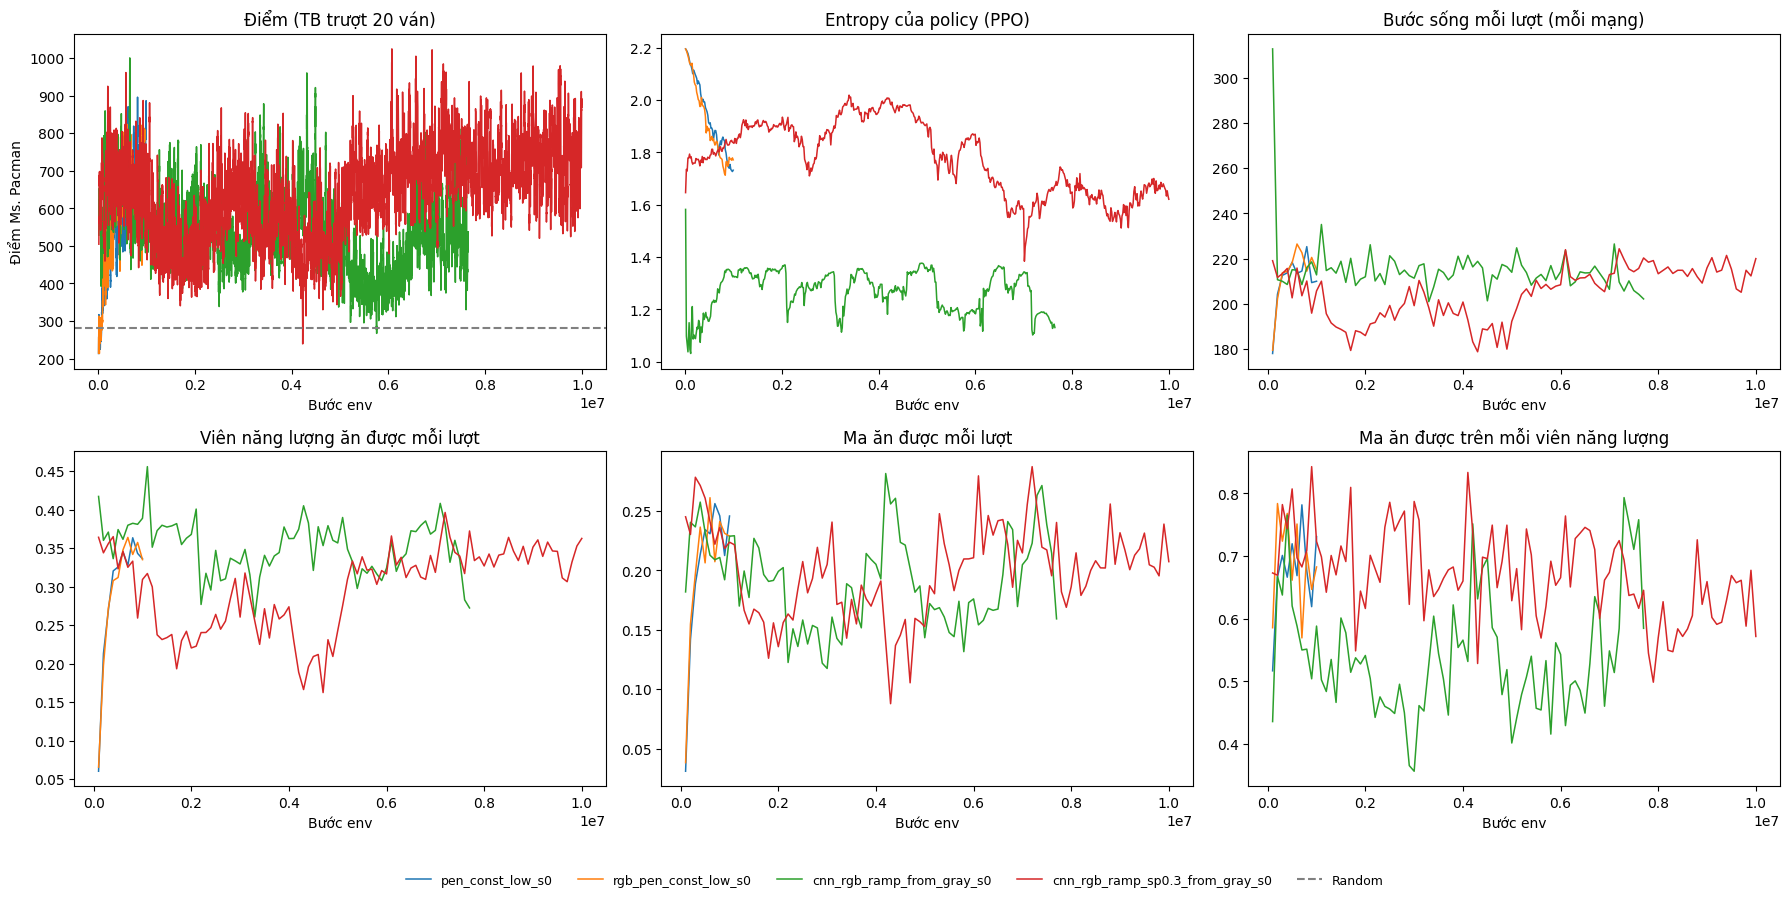

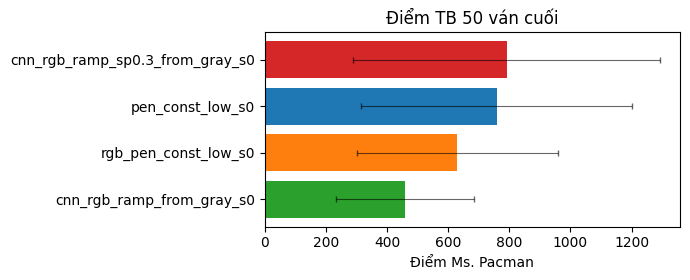

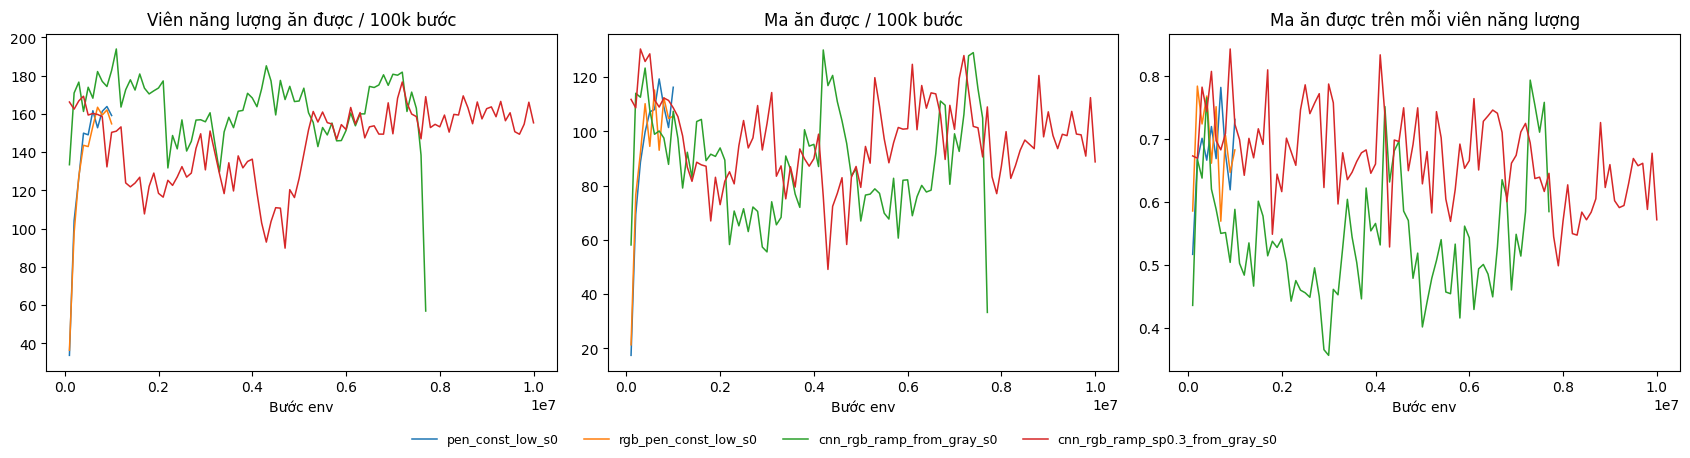

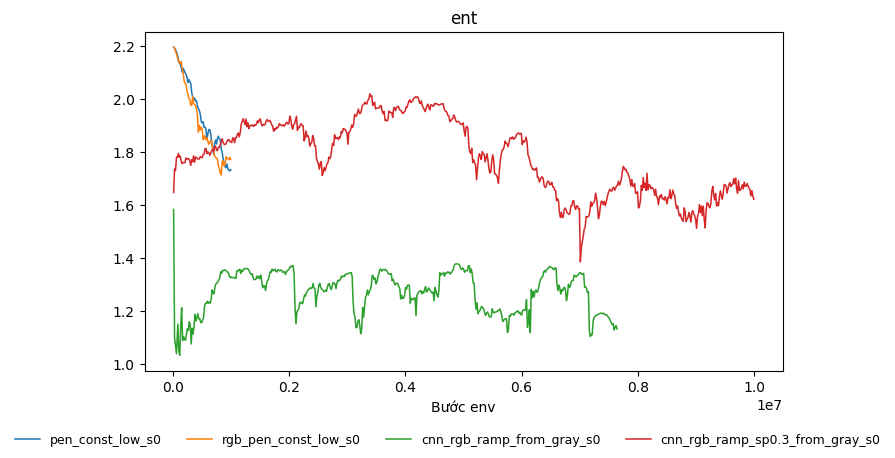

In [17]:
names = [SRC, SCRATCH_RGB] + ([OLD_RUN] if (Path(RUN_DIR) / f"{OLD_RUN}.pt").exists() else []) + [DST]
runs = compare(names=names, directory=RUN_DIR, random_scores=random_baseline(5),
               metrics=("ent",), device=device, save_path=f"{RUN_DIR}/{DST}_compare.png")

## 4. Chấm điểm (seed cố định, cùng ván cho mọi model)
Điểm là điểm game thật, nên so được giữa các run.

In [11]:
N_EVAL = 3 if SMOKE else 20
rows = {}
for n in names:
    model = load_run(RUN_DIR, n, "ppo", device).model.to(device).eval()
    rows[n] = evaluate(ppo_policy(model, device), n_episodes=N_EVAL, seed=1000)
    print(f"{n:40s} TB {np.mean(rows[n]):7.0f} | std {np.std(rows[n]):6.0f} | max {np.max(rows[n]):6.0f}")
json.dump({n: [float(x) for x in v] for n, v in rows.items()}, open(f"{RUN_DIR}/{DST}_eval.json", "w"))

pen_const_low_s0                         TB     608 | std    434 | max   2290
rgb_pen_const_low_s0                     TB     773 | std    466 | max   1890
cnn_rgb_ramp_from_gray_s0                TB     510 | std    306 | max   1190
cnn_rgb_ramp_sp0.3_from_gray_s0          TB     626 | std    321 | max   1290


## 5. Hành vi quanh ma xanh / ma thường
Pha "ma ăn được" = `W` bước agent sau khi ăn viên năng lượng (reward 50 hoặc 60), pha còn lại = "ma nguy hiểm". Khoảng cách tới con ma gần nhất lấy từ RAM ALE
(byte 6..9 / 12..15 là x / y của ma, byte 10 / 16 là x / y của Pacman, theo bảng AtariARI, **chưa được kiểm lại** với Ms. Pacman). `W` cũng là ước lượng.
Cột "đổi TB" âm nghĩa là agent đang lao tới ma, dương là đang rời xa. Nếu mạng phân biệt được màu thì hai pha phải khác nhau (lao tới ở pha ma xanh, né ở pha ma thường).

In [12]:
def ghost_diag(model, n_ep=8, W=80, NEAR=40, seed=1000):
    model = model.to(device).eval()
    act = ppo_policy(model, device)
    env = make_env(rgb_scale=model.in_channels == 12)
    ale = env.unwrapped.ale
    def nearest():
        ram = ale.getRAM(); px, py = int(ram[10]), int(ram[16])
        return min(abs(int(ram[6 + i]) - px) + abs(int(ram[12 + i]) - py) for i in range(4))
    st = {k: dict(steps=0, close=0, delta=[], deaths=0, eaten=0) for k in ("ma ăn được", "ma nguy hiểm")}
    scores = []
    try:
        for ep in range(n_ep):
            obs, _ = env.reset(seed=seed + ep); act.reset()
            t_pp, lives, done, sc, steps = -10**9, ale.lives(), False, 0.0, 0
            d_prev = nearest()
            while not done and steps < 4500:
                ph = "ma ăn được" if steps - t_pp < W else "ma nguy hiểm"
                obs, r, te, tr, _ = env.step(act(np.asarray(obs)))
                steps += 1; sc += r; done = te or tr
                s = st[ph]; s["steps"] += 1
                d = nearest()
                if d_prev < NEAR: s["close"] += 1; s["delta"].append(d - d_prev)
                d_prev = d
                if r in (50, 60): t_pp = steps
                if ph == "ma ăn được" and r in (200, 400, 800, 1600, 210, 410, 810, 1610): s["eaten"] += 1
                l = ale.lives()
                if l < lives: s["deaths"] += 1
                lives = l
            scores.append(sc)
    finally:
        env.close()
    return scores, st

N_DIAG = 2 if SMOKE else 8
for n in [SRC, DST]:
    model = load_run(RUN_DIR, n, "ppo", device).model
    scores, st = ghost_diag(model, N_DIAG)
    print(f"\n== {n} | {N_DIAG} ván, điểm TB {np.mean(scores):.0f} ==")
    for k, s in st.items():
        dl = np.array(s["delta"]) if s["delta"] else np.array([np.nan])
        print(f"{k:13s}: {s['steps']:6d} bước | gần ma: {s['close']:5d} | đổi TB {np.nanmean(dl):+.2f}/bước | chết {s['deaths']:2d} | ăn ma {s['eaten']:2d}")


== pen_const_low_s0 | 8 ván, điểm TB 552 ==
ma ăn được   :    720 bước | gần ma:    15 | đổi TB +0.27/bước | chết  0 | ăn ma  0
ma nguy hiểm :   4619 bước | gần ma:  2340 | đổi TB +0.09/bước | chết 24 | ăn ma  0

== cnn_rgb_ramp_sp0.3_from_gray_s0 | 8 ván, điểm TB 481 ==
ma ăn được   :    400 bước | gần ma:    36 | đổi TB +3.36/bước | chết  0 | ăn ma  0
ma nguy hiểm :   4097 bước | gần ma:  2514 | đổi TB +0.13/bước | chết 24 | ăn ma  0


## 6. Xem model vừa train chơi (cần màn hình)

In [14]:
from pacman_rl.evaluation import watch
watch(ppo_policy(load_run(RUN_DIR, DST, "ppo", device).model.to(device).eval(), device, greedy=True), episodes=1)

[play] ván 1: 210 điểm (371 bước)


[210.0]